# Experiment 2: a 1D-CNN architecture benchmark

This notebook keeps the same simple Experiment 2 task as the original notebook:

- simulate datasets from **Exponential, Log-normal, and Gamma** models;
- draw each dataset's parameter from the same prior as before;
- give all 100 observations to one neural network;
- predict both the model and its generating parameter; and
- evaluate model classification and parameter estimation on held-out data.

The only main experimental change is the shared neural-network architecture. The original benchmark used a dense network, `100 → 128 → 64`. This notebook uses a modest **one-dimensional convolutional neural network (1D CNN)**. Therefore, this is an **architecture comparison / second measurement**, not a claim that the new network is an improvement.

This is also a standalone neural network experiment. It is **not NN-ABC**: there is no ABC acceptance step after the neural network.

## 1. Imports and reproducibility

The random seeds make the simulation and training approximately reproducible. Exact TensorFlow results can still vary slightly across hardware.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Input, layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 10
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 2. Experiment settings

One neural-network example is an entire dataset containing 100 observations. The default of 30,000 datasets keeps the notebook practical on an ordinary computer. For a report-scale run, change `NUM_DATASETS` to `1_000_000`. Use the **same value** when running the original dense network and this CNN so that the architecture comparison is fair.

In [2]:
NUM_DATASETS = 30_000       # Set to 1_000_000 for the original large-scale setting
SAMPLE_SIZE = 100
TEST_SIZE = 0.20
EPOCHS = 15
BATCH_SIZE = 64

N_PER_MODEL = NUM_DATASETS // 3
NUM_DATASETS = 3 * N_PER_MODEL  # keep the three model classes exactly balanced
MODEL_NAMES = np.array(["Exponential", "Log-normal", "Gamma"])

print(f"Datasets: {NUM_DATASETS:,} ({N_PER_MODEL:,} per model)")
print(f"Observations per dataset: {SAMPLE_SIZE}")

Datasets: 30,000 (10,000 per model)
Observations per dataset: 100


## 3. Simulate the same three-model prior-predictive task

For every row, the code first draws one parameter and then generates 100 conditionally independent observations using that parameter. The models and priors are unchanged:

- Model 0: `theta ~ Exp(1)`, then `Y_j | theta ~ Exponential(rate=theta)`.
- Model 1: `theta ~ Normal(0,1)`, then `Y_j | theta ~ LogNormal(location=theta, sigma=1)`.
- Model 2: `theta ~ Exp(1)`, then `Y_j | theta ~ Gamma(shape=2, rate=theta)`.

NumPy parameterizes Exponential and Gamma with a scale, so the code uses `scale = 1 / theta` when `theta` is a rate.

In [3]:
# Exponential(rate=theta), theta ~ Exp(1)
theta_exp = np.random.exponential(scale=1.0, size=N_PER_MODEL)
x_exp = np.random.exponential(
    scale=1.0 / theta_exp[:, None],
    size=(N_PER_MODEL, SAMPLE_SIZE),
)

# Log-normal(location=theta, sigma=1), theta ~ N(0,1)
theta_logn = np.random.normal(loc=0.0, scale=1.0, size=N_PER_MODEL)
x_logn = np.random.lognormal(
    mean=theta_logn[:, None],
    sigma=1.0,
    size=(N_PER_MODEL, SAMPLE_SIZE),
)

# Gamma(shape=2, rate=theta), theta ~ Exp(1)
theta_gamma = np.random.exponential(scale=1.0, size=N_PER_MODEL)
x_gamma = np.random.gamma(
    shape=2.0,
    scale=1.0 / theta_gamma[:, None],
    size=(N_PER_MODEL, SAMPLE_SIZE),
)

## 4. Assemble inputs and targets

The input remains the raw 100-observation dataset, followed by the same element-wise `arcsinh` transform used in the original notebook. No handcrafted summary statistics are added.

There are two targets:

1. `y_class`: which of the three models generated the row;
2. `y_param`: the actual parameter drawn before that row was simulated.

Pairing each simulated dataset with its own generating parameter makes parameter estimation a meaningful supervised task.

In [4]:
X = np.vstack([x_exp, x_logn, x_gamma]).astype("float32")
X = np.arcsinh(X).astype("float32")

class_ids = np.concatenate([
    np.zeros(N_PER_MODEL, dtype="int32"),
    np.ones(N_PER_MODEL, dtype="int32"),
    np.full(N_PER_MODEL, 2, dtype="int32"),
])
y_class = to_categorical(class_ids, num_classes=3).astype("float32")

y_param = np.concatenate([theta_exp, theta_logn, theta_gamma]).astype("float32")
y_param = y_param.reshape(-1, 1)

del x_exp, x_logn, x_gamma, theta_exp, theta_logn, theta_gamma

print("X shape:      ", X.shape)
print("Class shape:  ", y_class.shape)
print("Parameter shape:", y_param.shape)

X shape:       (30000, 100)
Class shape:   (30000, 3)
Parameter shape: (30000, 1)


## 5. Make one stratified train/test split

Twenty percent of the simulated datasets are held out for final testing. Stratification preserves the equal mixture of the three models in both parts. The CNN needs a final channel dimension, so each input changes from shape `(100,)` to `(100, 1)` without changing its values.

In [5]:
indices = np.arange(NUM_DATASETS)
train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=42,
    stratify=class_ids,
)

X_train = X[train_idx, :, None]
X_test = X[test_idx, :, None]
y_class_train, y_class_test = y_class[train_idx], y_class[test_idx]
y_param_train, y_param_test = y_param[train_idx], y_param[test_idx]
class_ids_train, class_ids_test = class_ids[train_idx], class_ids[test_idx]

del X, y_class, y_param, indices, train_idx, test_idx
print("Training input:", X_train.shape)
print("Test input:    ", X_test.shape)

Training input: (24000, 100, 1)
Test input:     (6000, 100, 1)


## 6. Define the alternative 1D-CNN architecture

The original shared representation was made by two dense layers (`100 → 128 → 64`). Here, small convolution filters scan across the 100 transformed values. Global average pooling then converts the filter responses into one compact learned embedding. Two output heads use that same embedding:

`100 observations → Conv1D blocks → learned embedding → model probabilities + parameter estimate`

This is a modest architecture change, while the simulation, inputs, outputs, loss functions, and evaluation criteria remain comparable. A 1D CNN is not fully invariant to arbitrary permutations of i.i.d. observations; it is used here specifically as a simple architecture benchmark inspired by the report, not as a theoretical solution to permutation invariance.

In [6]:
inputs = Input(shape=(SAMPLE_SIZE, 1), name="dataset")

x = layers.Conv1D(32, kernel_size=5, padding="same", activation="relu")(inputs)
x = layers.MaxPooling1D(pool_size=2)(x)
x = layers.Conv1D(64, kernel_size=5, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
embedding = layers.Dense(64, activation="relu", name="learned_embedding")(x)

class_output = layers.Dense(3, activation="softmax", name="class_output")(embedding)
param_output = layers.Dense(1, activation="linear", name="param_output")(embedding)

model = models.Model(
    inputs=inputs,
    outputs={"class_output": class_output, "param_output": param_output},
    name="experiment_2_cnn_benchmark",
)

model.summary()

Model: "experiment_2_cnn_benchmark"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dataset             │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 100, 32)   │        192 │ dataset[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 50, 32)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 50, 64)    │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv1d_1[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ learned_embedding   │ (None, 64)        │      4,160 │ global_average_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │        195 │ learned_embeddin… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ param_output        │ (None, 1)         │         65 │ learned_embeddin… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,916 (58.27 KB)

 Trainable params: 14,916 (58.27 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile and train

As in the original multi-task experiment, categorical cross-entropy trains model classification and mean squared error trains parameter estimation. The total objective is

`total loss = classification loss + 0.5 × parameter loss`.

A validation split monitors both tasks during training. Early stopping is only a practical safeguard: it restores the epoch with the best validation loss.

In [7]:
model.compile(
    optimizer="adam",
    loss={
        "class_output": "categorical_crossentropy",
        "param_output": "mse",
    },
    loss_weights={"class_output": 1.0, "param_output": 0.5},
    metrics={
        "class_output": ["accuracy"],
        "param_output": ["mae"],
    },
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    X_train,
    {"class_output": y_class_train, "param_output": y_param_train},
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - class_output_accuracy: 0.5644 - class_output_loss: 0.8218 - loss: 1.3890 - param_output_loss: 1.1343 - param_output_mae: 0.7289 - val_class_output_accuracy: 0.6744 - val_class_output_loss: 0.5632 - val_loss: 1.0402 - val_param_output_loss: 0.9541 - val_param_output_mae: 0.6631
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - class_output_accuracy: 0.6981 - class_output_loss: 0.5336 - loss: 0.9876 - param_output_loss: 0.9080 - param_output_mae: 0.6207 - val_class_output_accuracy: 0.6842 - val_class_output_loss: 0.5322 - val_loss: 0.9460 - val_param_output_loss: 0.8277 - val_param_output_mae: 0.5801
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - class_output_accuracy: 0.7515 - class_output_loss: 0.4822 - loss: 0.9059 - param_output_loss: 0.8474 - param_output_mae: 0.5877 - val_class_output_accuracy: 0.7292 - val_class_output_loss: 0.4931 - val_loss: 0.8884 - val_param_output_loss: 0.7907 - val_param_output_mae: 0.5517
Epoc

## 8. Plot the training history

These plots help distinguish training behaviour from final test performance. They are descriptive measurements, not evidence that one architecture is inherently better.

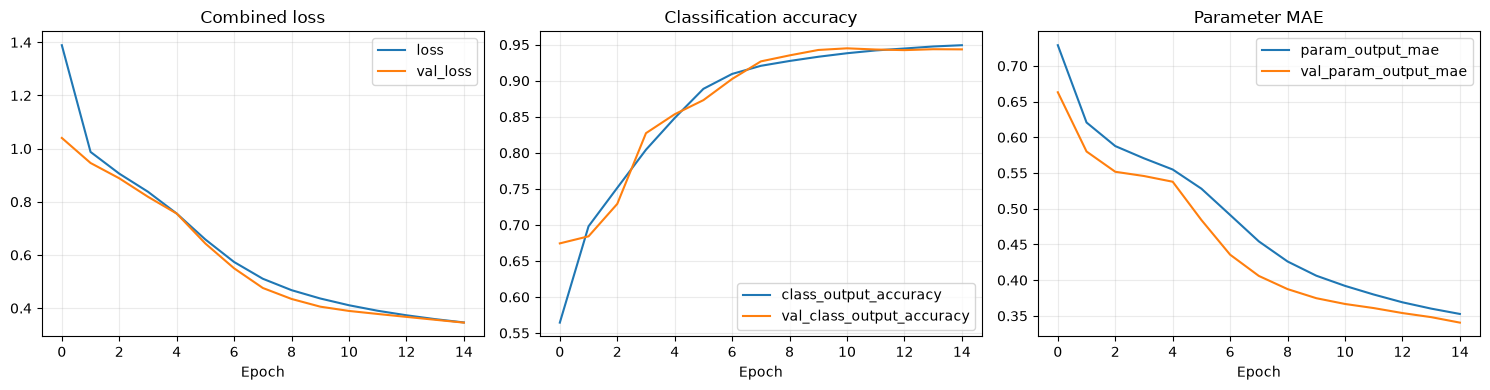

In [8]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
history_df[["loss", "val_loss"]].plot(ax=axes[0], title="Combined loss")
history_df[["class_output_accuracy", "val_class_output_accuracy"]].plot(
    ax=axes[1], title="Classification accuracy"
)
history_df[["param_output_mae", "val_param_output_mae"]].plot(
    ax=axes[2], title="Parameter MAE"
)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Evaluate on held-out prior-predictive datasets

The two main comparable measurements are classification accuracy and parameter mean absolute error (MAE). `return_dict=True` avoids relying on a version-dependent position in Keras's result list.

In [9]:
test_metrics = model.evaluate(
    X_test,
    {"class_output": y_class_test, "param_output": y_param_test},
    return_dict=True,
    verbose=0,
)

print("Held-out test measurements")
for name, value in test_metrics.items():
    print(f"{name:30s}: {value:.4f}")

Held-out test measurements
class_output_accuracy         : 0.9517
class_output_loss             : 0.1382
loss                          : 0.3016
param_output_loss             : 0.3270
param_output_mae              : 0.3274


## 10. Inspect predictions by model

Class predictions use the largest predicted probability (`argmax`). This is deterministic and is the standard way to calculate classification accuracy; randomly sampling a label from the predicted probabilities would add unnecessary evaluation noise.

The table also reports parameter MAE separately for each true model, because a single overall MAE can hide model-specific differences.

In [10]:
pred = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
class_prob = pred["class_output"]
param_pred = pred["param_output"].ravel()
class_pred = class_prob.argmax(axis=1)
param_true = y_param_test.ravel()

overall_accuracy = np.mean(class_pred == class_ids_test)
overall_mae = np.mean(np.abs(param_pred - param_true))
print(f"Overall classification accuracy: {overall_accuracy:.4f}")
print(f"Overall parameter MAE:          {overall_mae:.4f}")

rows = []
for model_id, model_name in enumerate(MODEL_NAMES):
    mask = class_ids_test == model_id
    rows.append({
        "model": model_name,
        "n_test": int(mask.sum()),
        "classification_accuracy": np.mean(class_pred[mask] == class_ids_test[mask]),
        "parameter_mae": np.mean(np.abs(param_pred[mask] - param_true[mask])),
    })

per_model_results = pd.DataFrame(rows)
per_model_results

Overall classification accuracy: 0.9517
Overall parameter MAE:          0.3274


,model,n_test,classification_accuracy,parameter_mae
0,Exponential,2000,0.9280,0.368495
1,Log-normal,2000,0.9645,0.397406
2,Gamma,2000,0.9625,0.216445


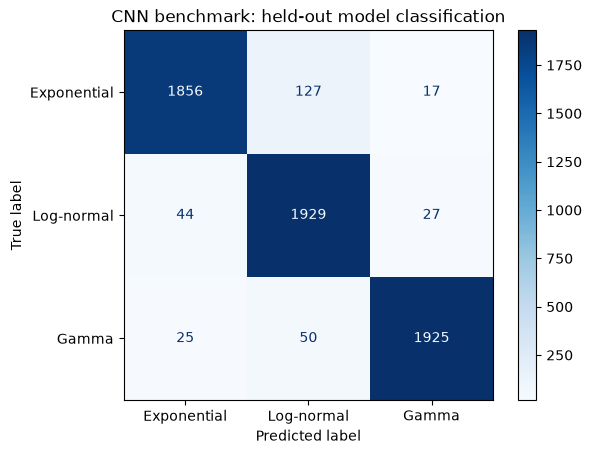

In [11]:
cm = confusion_matrix(class_ids_test, class_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=MODEL_NAMES).plot(cmap="Blues")
plt.title("CNN benchmark: held-out model classification")
plt.show()

## 11. Fixed-parameter test used in the original notebook

The held-out test above samples parameters from the priors. This second test keeps the original notebook's three fixed parameter settings: Exponential rate `0.5`, Log-normal location `log(2)-0.5`, and Gamma rate `1`. It contains 100 newly simulated datasets from each model.

This does not replace the held-out test. It is an additional, easily interpreted measurement at three particular parameter values.

In [12]:
FIXED_TEST_SEED = 42
N_FIXED_PER_MODEL = 100
rng = np.random.default_rng(FIXED_TEST_SEED)

fixed_exp_theta = 0.5
fixed_logn_theta = np.log(2.0) - 0.5
fixed_gamma_theta = 1.0

fixed_exp = rng.exponential(
    scale=1.0 / fixed_exp_theta, size=(N_FIXED_PER_MODEL, SAMPLE_SIZE)
)
fixed_logn = rng.lognormal(
    mean=fixed_logn_theta, sigma=1.0, size=(N_FIXED_PER_MODEL, SAMPLE_SIZE)
)
fixed_gamma = rng.gamma(
    shape=2.0, scale=1.0 / fixed_gamma_theta, size=(N_FIXED_PER_MODEL, SAMPLE_SIZE)
)

X_fixed = np.arcsinh(np.vstack([fixed_exp, fixed_logn, fixed_gamma])).astype("float32")
X_fixed = X_fixed[:, :, None]
fixed_class_true = np.repeat(np.arange(3), N_FIXED_PER_MODEL)
fixed_param_true = np.repeat(
    [fixed_exp_theta, fixed_logn_theta, fixed_gamma_theta], N_FIXED_PER_MODEL
).astype("float32")

fixed_pred = model.predict(X_fixed, batch_size=BATCH_SIZE, verbose=0)
fixed_prob = fixed_pred["class_output"]
fixed_param_pred = fixed_pred["param_output"].ravel()
fixed_class_pred = fixed_prob.argmax(axis=1)

print(f"Fixed-test classification accuracy: {np.mean(fixed_class_pred == fixed_class_true):.4f}")
print(f"Fixed-test parameter MAE:          {np.mean(np.abs(fixed_param_pred - fixed_param_true)):.4f}")

Fixed-test classification accuracy: 0.9533
Fixed-test parameter MAE:          0.1389


In [13]:
fixed_rows = []
for model_id, model_name in enumerate(MODEL_NAMES):
    mask = fixed_class_true == model_id
    fixed_rows.append({
        "model": model_name,
        "true_parameter": fixed_param_true[mask][0],
        "classification_accuracy": np.mean(fixed_class_pred[mask] == fixed_class_true[mask]),
        "mean_parameter_estimate": np.mean(fixed_param_pred[mask]),
        "parameter_mae": np.mean(np.abs(fixed_param_pred[mask] - fixed_param_true[mask])),
    })

fixed_results = pd.DataFrame(fixed_rows)
fixed_results

,model,true_parameter,classification_accuracy,mean_parameter_estimate,parameter_mae
0,Exponential,0.500000,0.94,0.418719,0.163064
1,Log-normal,0.193147,0.97,0.225418,0.130396
2,Gamma,1.000000,0.95,0.919658,0.123390


## 12. Save comparable measurements

The CSV files make it easy to place the CNN measurements beside results from the original `100 → 128 → 64` feed-forward network. Run both architectures with the same simulation size, split, fixed test, and metrics before comparing them.

In [14]:
summary = pd.DataFrame([{
    "architecture": "1D CNN",
    "num_datasets": NUM_DATASETS,
    "sample_size": SAMPLE_SIZE,
    "held_out_accuracy": overall_accuracy,
    "held_out_parameter_mae": overall_mae,
    "fixed_test_accuracy": np.mean(fixed_class_pred == fixed_class_true),
    "fixed_test_parameter_mae": np.mean(np.abs(fixed_param_pred - fixed_param_true)),
}])

summary.to_csv("cnn_benchmark_summary.csv", index=False)
per_model_results.to_csv("cnn_benchmark_held_out_by_model.csv", index=False)
fixed_results.to_csv("cnn_benchmark_fixed_test_by_model.csv", index=False)
summary

,architecture,num_datasets,sample_size,held_out_accuracy,held_out_parameter_mae,fixed_test_accuracy,fixed_test_parameter_mae
0,1D CNN,30000,100,0.951667,0.327449,0.953333,0.13895


## 13. Train the original feed-forward network on the identical split

For a fair architecture comparison, this section trains the original `100 → 128 → 64` feed-forward neural network (FFNN) using exactly the same training rows, validation procedure, targets, loss weights, and held-out test rows as the CNN. The only intended difference is the hidden architecture.

In [15]:
ffnn_inputs = Input(shape=(SAMPLE_SIZE,), name="dataset")
ffnn_x = layers.Dense(128, activation="relu")(ffnn_inputs)
ffnn_embedding = layers.Dense(64, activation="relu", name="ffnn_embedding")(ffnn_x)
ffnn_class = layers.Dense(3, activation="softmax", name="class_output")(ffnn_embedding)
ffnn_param = layers.Dense(1, activation="linear", name="param_output")(ffnn_embedding)

ffnn_model = models.Model(
    inputs=ffnn_inputs,
    outputs={"class_output": ffnn_class, "param_output": ffnn_param},
    name="original_ffnn_benchmark",
)
ffnn_model.compile(
    optimizer="adam",
    loss={"class_output": "categorical_crossentropy", "param_output": "mse"},
    loss_weights={"class_output": 1.0, "param_output": 0.5},
    metrics={"class_output": ["accuracy"], "param_output": ["mae"]},
)

ffnn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
ffnn_history = ffnn_model.fit(
    X_train[:, :, 0],
    {"class_output": y_class_train, "param_output": y_param_train},
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[ffnn_early_stopping],
    verbose=1,
)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 692us/step - class_output_accuracy: 0.4719 - class_output_loss: 0.9755 - loss: 1.6341 - param_output_loss: 1.3171 - param_output_mae: 0.8145 - val_class_output_accuracy: 0.5156 - val_class_output_loss: 0.9089 - val_loss: 1.5051 - val_param_output_loss: 1.1922 - val_param_output_mae: 0.7458
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 444us/step - class_output_accuracy: 0.5387 - class_output_loss: 0.8807 - loss: 1.4545 - param_output_loss: 1.1477 - param_output_mae: 0.7460 - val_class_output_accuracy: 0.5431 - val_class_output_loss: 0.8629 - val_loss: 1.4159 - val_param_output_loss: 1.1060 - val_param_output_mae: 0.7072
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step - class_output_accuracy: 0.5872 - class_output_loss: 0.7961 - loss: 1.3319 - param_output_loss: 1.0716 - param_output_mae: 0.7198 - val_class_output_accuracy: 0.6054 - val_class_output_loss: 0.7591 - val_loss: 1.2803 - val_param_output_loss: 1.0425 - val_param_output_mae: 0.688

## 14. Generate paired predictions

Both architectures now predict the same held-out datasets. This creates a paired comparison: every FFNN error and CNN error refers to exactly the same simulated dataset.

In [16]:
ffnn_pred = ffnn_model.predict(X_test[:, :, 0], batch_size=BATCH_SIZE, verbose=0)
ffnn_prob = ffnn_pred["class_output"]
ffnn_param_pred = ffnn_pred["param_output"].ravel()
ffnn_class_pred = ffnn_prob.argmax(axis=1)

cnn_accuracy = np.mean(class_pred == class_ids_test)
ffnn_accuracy = np.mean(ffnn_class_pred == class_ids_test)
cnn_abs_error = np.abs(param_pred - param_true)
ffnn_abs_error = np.abs(ffnn_param_pred - param_true)
cnn_mae = cnn_abs_error.mean()
ffnn_mae = ffnn_abs_error.mean()

row_ids = np.arange(len(class_ids_test))
cnn_true_confidence = class_prob[row_ids, class_ids_test]
ffnn_true_confidence = ffnn_prob[row_ids, class_ids_test]

comparison_metrics = pd.DataFrame({
    "architecture": ["Original FFNN", "1D CNN"],
    "classification_accuracy": [ffnn_accuracy, cnn_accuracy],
    "parameter_mae": [ffnn_mae, cnn_mae],
})
comparison_metrics

,architecture,classification_accuracy,parameter_mae
0,Original FFNN,0.646833,0.614195
1,1D CNN,0.951667,0.327449


## 15. Overall comparison bars

The left panel compares classification accuracy, where higher is better. The right panel compares parameter MAE, where lower is better. These bars provide a simple summary, while the later plots show where the differences come from.

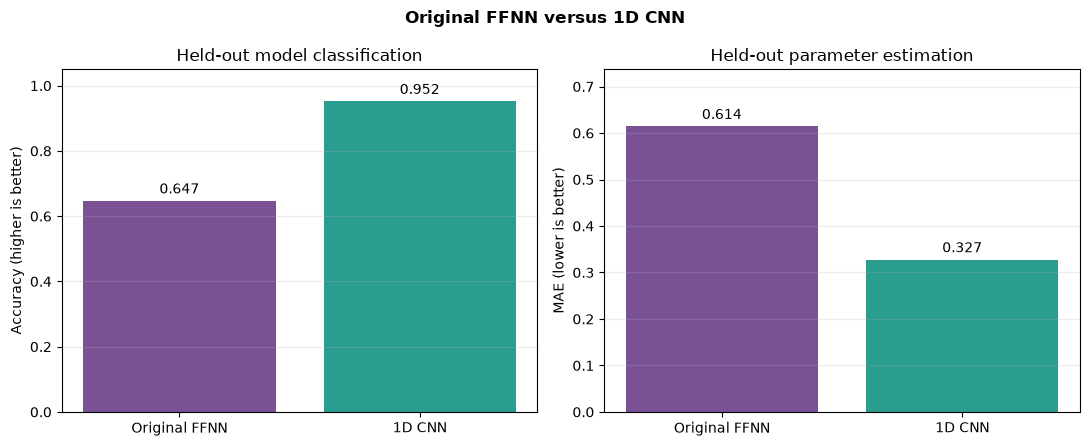

In [17]:
colors = ["#7A5195", "#2A9D8F"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bars = axes[0].bar(comparison_metrics["architecture"], comparison_metrics["classification_accuracy"], color=colors)
axes[0].set_title("Held-out model classification")
axes[0].set_ylabel("Accuracy (higher is better)")
axes[0].set_ylim(0, 1.05)
axes[0].bar_label(bars, fmt="%.3f", padding=3)

bars = axes[1].bar(comparison_metrics["architecture"], comparison_metrics["parameter_mae"], color=colors)
axes[1].set_title("Held-out parameter estimation")
axes[1].set_ylabel("MAE (lower is better)")
axes[1].bar_label(bars, fmt="%.3f", padding=3)
axes[1].set_ylim(0, max(comparison_metrics["parameter_mae"]) * 1.2)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.suptitle("Original FFNN versus 1D CNN", fontweight="bold")
plt.tight_layout()
plt.show()

## 16. Normalized confusion matrices

Each row adds to 100%, so the two architectures can be compared even if class counts change in a later run. The diagonal contains correct classifications; off-diagonal cells show which models are confused.

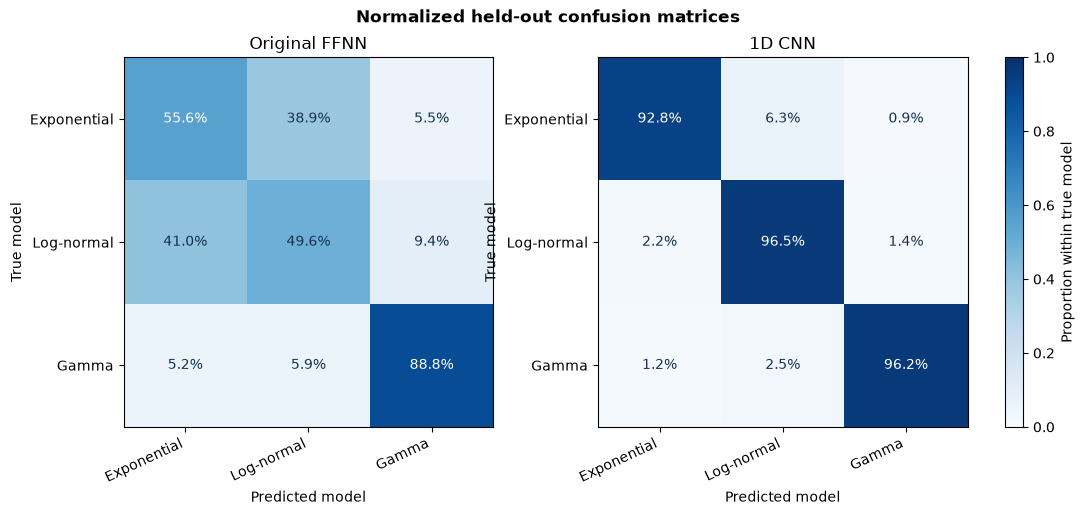

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, predicted, title in zip(
    axes,
    [ffnn_class_pred, class_pred],
    ["Original FFNN", "1D CNN"],
):
    matrix = confusion_matrix(class_ids_test, predicted, labels=[0, 1, 2], normalize="true")
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(3), MODEL_NAMES, rotation=25, ha="right")
    ax.set_yticks(range(3), MODEL_NAMES)
    ax.set_xlabel("Predicted model")
    ax.set_ylabel("True model")
    for row in range(3):
        for col in range(3):
            text_color = "white" if matrix[row, col] > 0.5 else "#16324F"
            ax.text(col, row, f"{matrix[row, col]:.1%}", ha="center", va="center", color=text_color)
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.04, label="Proportion within true model")
fig.suptitle("Normalized held-out confusion matrices", fontweight="bold")
plt.show()

## 17. Parameter-error box plots

Each box contains the absolute parameter errors for one architecture and one true model. A lower median and a shorter box indicate more accurate and more consistent parameter estimation. Outlier points are hidden only to keep the main boxes readable; the underlying errors are not removed from any calculations.

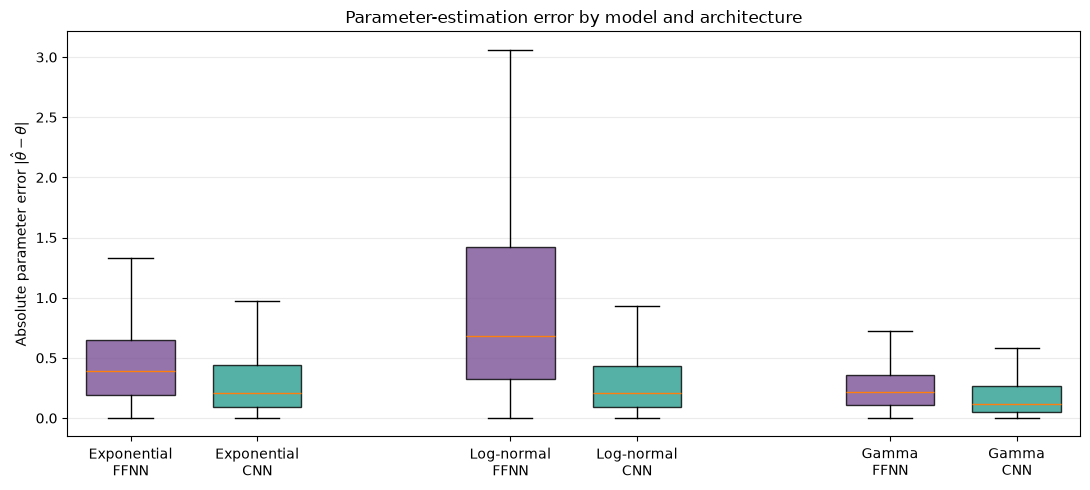

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
box_data, positions, labels, box_colors = [], [], [], []
for model_id, model_name in enumerate(MODEL_NAMES):
    mask = class_ids_test == model_id
    base = 3 * model_id + 1
    box_data.extend([ffnn_abs_error[mask], cnn_abs_error[mask]])
    positions.extend([base, base + 1])
    labels.extend([f"{model_name}\nFFNN", f"{model_name}\nCNN"])
    box_colors.extend(colors)

boxes = ax.boxplot(box_data, positions=positions, widths=0.7, patch_artist=True, showfliers=False)
for patch, color in zip(boxes["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_xticks(positions, labels)
ax.set_ylabel(r"Absolute parameter error $|\hat{\theta}-\theta|$")
ax.set_title("Parameter-estimation error by model and architecture")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 18. Correct-model confidence box plots

Accuracy records only whether the largest probability was correct. These boxes instead show the probability assigned to the true model for every dataset. Higher values indicate that the architecture is more confident in the correct answer. Confidence is not the same as calibration, so this plot should be interpreted descriptively.

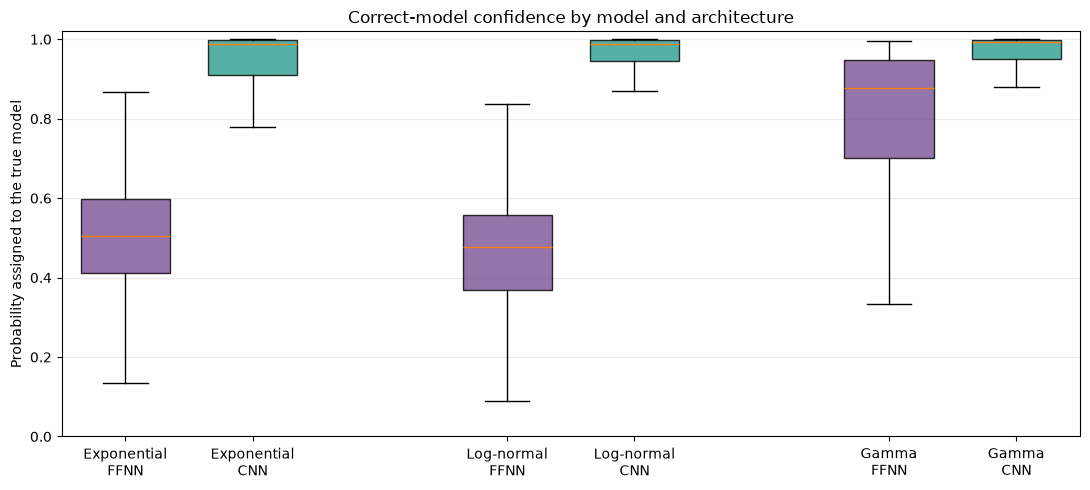

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
confidence_data, positions, labels, box_colors = [], [], [], []
for model_id, model_name in enumerate(MODEL_NAMES):
    mask = class_ids_test == model_id
    base = 3 * model_id + 1
    confidence_data.extend([ffnn_true_confidence[mask], cnn_true_confidence[mask]])
    positions.extend([base, base + 1])
    labels.extend([f"{model_name}\nFFNN", f"{model_name}\nCNN"])
    box_colors.extend(colors)

boxes = ax.boxplot(confidence_data, positions=positions, widths=0.7, patch_artist=True, showfliers=False)
for patch, color in zip(boxes["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_xticks(positions, labels)
ax.set_ylim(0, 1.02)
ax.set_ylabel("Probability assigned to the true model")
ax.set_title("Correct-model confidence by model and architecture")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 19. Save the comparison table

This small table records the headline results used by the bar chart. The per-dataset predictions remain in memory for the box plots above.

In [21]:
comparison_metrics.to_csv("ffnn_vs_cnn_metrics.csv", index=False)
comparison_metrics

,architecture,classification_accuracy,parameter_mae
0,Original FFNN,0.646833,0.614195
1,1D CNN,0.951667,0.327449


## Interpretation

This notebook provides a **second architecture measurement** under the same three-model experiment. A higher or lower score is an empirical result for this simulation and training run; the notebook does not assume in advance that the CNN improves on the dense network.

A fair comparison should report, for both architectures:

- the same number of simulated training datasets;
- held-out classification accuracy;
- held-out parameter MAE;
- model-specific results and a confusion matrix; and
- the same fixed-parameter test results.

The 64-unit `learned_embedding` layer is a learned representation of each dataset. In an NN-ABC study it could later be extracted and used as an ABC summary, but that separate ABC procedure is intentionally **not included here**.